# Selección del modelo de P2 para producción — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P2 (clasificación) · Semana 6<br>
**Autor:** Roberto Robles · **Rama:** `feature/p2-mlflow-experimentos`<br>
**Antecedentes:** `2.1-rr-p2-particion-validacion.ipynb` (referencia de la partición y del baseline) y `2.2-rr-p2-mlflow-corridas-artefactos.ipynb` (comprobación de las corridas oficiales).

**Propósito.** Comparar las corridas oficiales de P2 (lanzadas con `mlflow run` y comprobadas en el notebook 2.2) y decidir, de forma justificada, qué modelo pasa a producción (alias `champion`) y cuál queda como siguiente mejor (`challenger`). La actividad pide considerar cuatro criterios:

1. **Mejora contra el baseline.**
2. **La métrica ligada a la decisión de negocio:** F1 de fallas (que se anticipen las fallas reales con alertas que justifiquen el viaje del camión de rebalanceo).
3. **Estabilidad** de los resultados.
4. **Costo** de entrenamiento o inferencia.

**Regla.** Se **elige con validación** y se **confirma con prueba**. Si eligiéramos con la prueba, su resultado ya no sería una estimación honesta de cómo le irá al modelo con datos nuevos.

**Salida.** La última celda guarda la decisión en `reports/p2_seleccion_modelo.json`. El script `equipo52_module/modeling/registrar_p2.py` lee ese archivo para registrar el modelo, ponerle los alias y probar que carga.

In [1]:
# Objetivo: conectarse al servidor real y traer las corridas oficiales de P2 (lanzadas con mlflow run).
# Resultado esperado: el baseline, la corrida padre de la búsqueda y las candidatas, todas con fuente PROJECT.

import json
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent))
from equipo52_module.config import MLFLOW_EXPERIMENT, MLFLOW_TRACKING_URI, PROJ_ROOT

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
cliente = mlflow.MlflowClient()
experimento = cliente.get_experiment_by_name(MLFLOW_EXPERIMENT)
oficiales = mlflow.search_runs(
    [experimento.experiment_id],
    filter_string="tags.question = 'p2' and attributes.status = 'FINISHED' and tags.`mlflow.source.type` = 'PROJECT'",
    order_by=["attributes.start_time DESC"])
print("Servidor:", MLFLOW_TRACKING_URI, "· corridas oficiales de P2:", len(oficiales))
oficiales[["tags.mlflow.runName", "tags.stage_of_work", "tags.model_family", "tags.commit", "start_time"]]

/Users/Roberto/Proyectos/equipo52_proyecto_mibici/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-24 16:58:51.150 | INFO     | equipo52_module.config:<module>:12 - PROJ_ROOT path is: /Users/Roberto/Proyectos/equipo52_proyecto_mibici


Servidor: http://127.0.0.1:5000 · corridas oficiales de P2: 5


,tags.mlflow.runName,tags.stage_of_work,tags.model_family,tags.commit,start_time
0,p2-hgb-postcovid-peso_fallas3,candidate,hgb,df567a8487d9f26f23b4fb3ab02418cee1d06d5c,2026-10-24 21:04:14.301000+00:00
1,p2-logistica-completo-peso_fallas3,candidate,logistica,df567a8487d9f26f23b4fb3ab02418cee1d06d5c,2026-10-24 20:52:15.208000+00:00
2,p2-hgb-completo-peso_fallas3,candidate,hgb,df567a8487d9f26f23b4fb3ab02418cee1d06d5c,2026-10-24 18:48:09.264000+00:00
3,p2-busqueda-hgb-completo,search,hgb,a22f8e0a6d49ad4710dbcfc4a4f165115e2cacea,2026-10-24 02:09:21.035000+00:00
4,p2-base-completo,baseline,baseline,a22f8e0a6d49ad4710dbcfc4a4f165115e2cacea,2026-10-24 01:59:14.298000+00:00


## 1. Candidatas contra el baseline

Si una configuración se corrió más de una vez, se toma la corrida más reciente. La **mejora** se mide en el F1 de fallas de **prueba** contra el baseline, en puntos y en porcentaje.

In [2]:
# Objetivo: armar la tabla comparativa (Tabla 2 del reporte) con el baseline y las candidatas.
# Resultado esperado: una fila por modelo, ordenada por F1 de fallas en validación.

def valor(fila, columna):
    return fila.get(columna) if columna in fila and pd.notna(fila.get(columna)) else None

ultimas = oficiales[oficiales["tags.stage_of_work"].isin(["baseline", "candidate"])].drop_duplicates("tags.mlflow.runName")
base = ultimas[ultimas["tags.stage_of_work"] == "baseline"].iloc[0]
f1_base_val, f1_base_test = base["metrics.val_f1_fallas"], base["metrics.test_f1_fallas"]

filas = []
for _, r in ultimas.iterrows():
    familia = r["tags.model_family"]
    filas.append({
        "run_id": r["run_id"], "corrida": r["tags.mlflow.runName"], "etapa": r["tags.stage_of_work"], "familia": familia,
        "periodo": valor(r, "params.periodo_script") or valor(r, "params.periodo"),
        "peso_fallas": valor(r, "params.peso_fallas"),
        "learning_rate": valor(r, "params.hgb_learning_rate") if familia == "hgb" else None,
        "val_f1": r["metrics.val_f1_fallas"], "test_f1": r["metrics.test_f1_fallas"],
        "test_recall_bicis": r["metrics.test_recall_sin_bicicletas"], "test_precision_bicis": r["metrics.test_precision_sin_bicicletas"],
        "test_recall_anclajes": r["metrics.test_recall_sin_anclajes"], "test_precision_anclajes": r["metrics.test_precision_sin_anclajes"],
        "mejora_test_puntos": r["metrics.test_f1_fallas"] - f1_base_test,
        "mejora_test_%": (r["metrics.test_f1_fallas"] / f1_base_test - 1) * 100,
        "caida_val_a_test": r["metrics.val_f1_fallas"] - r["metrics.test_f1_fallas"],
        "segundos_entrenamiento": valor(r, "metrics.segundos_entrenamiento"),
    })
comparacion = pd.DataFrame(filas).sort_values("val_f1", ascending=False).reset_index(drop=True)
comparacion.drop(columns="run_id").round(3)

,corrida,etapa,familia,periodo,peso_fallas,learning_rate,val_f1,test_f1,test_recall_bicis,test_precision_bicis,test_recall_anclajes,test_precision_anclajes,mejora_test_puntos,mejora_test_%,caida_val_a_test,segundos_entrenamiento
0,p2-hgb-completo-peso_fallas3,candidate,hgb,completo,3,0.1,0.483,0.449,0.481,0.369,0.537,0.434,0.044,10.891,0.034,250.0
1,p2-hgb-postcovid-peso_fallas3,candidate,hgb,postcovid,3,0.1,0.480,0.444,0.496,0.350,0.534,0.432,0.039,9.731,0.036,39.1
2,p2-base-completo,baseline,baseline,completo,NaN,NaN,0.442,0.405,0.333,0.387,0.437,0.467,0.000,0.000,0.037,0.0
3,p2-logistica-completo-peso_fallas3,candidate,logistica,completo,3,NaN,0.427,0.388,0.317,0.379,0.405,0.460,-0.017,-4.081,0.039,38.4


## 2. Estabilidad

Dos señales:
- **Caída de validación a prueba** (`caida_val_a_test`). El baseline baja unos 0.04 puntos porque la prueba tiene menos fallas (notebook 2.1). Un modelo que baje **mucho más** que eso es menos estable.
- **Sensibilidad en la búsqueda.** Si el F1 cambia poco entre `learning_rate` para un mismo `peso_fallas`, el resultado no depende de un ajuste fino.

Búsqueda: p2-busqueda-hgb-completo · mejor combinación: {"peso_fallas": 3.0, "learning_rate": 0.1} · tiempo total 33 min


learning_rate,0.05,0.1,diferencia
peso_fallas,,,
2.0,0.468,0.472,0.004
3.0,0.478,0.483,0.004
5.0,0.454,0.457,0.003
8.0,0.413,0.415,0.002


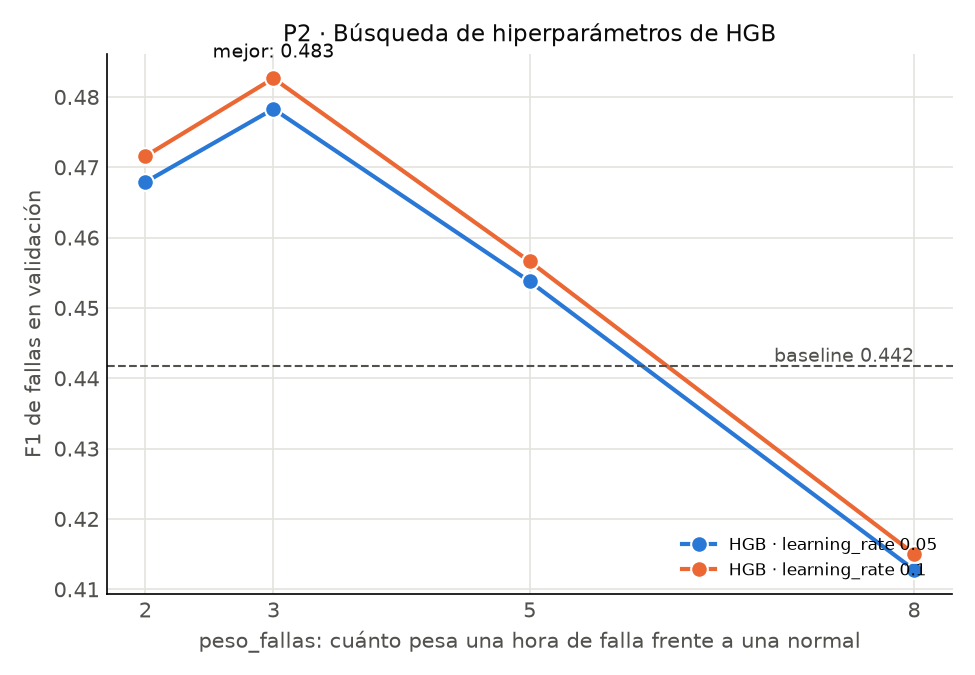

In [3]:
# Objetivo: leer la tabla de la búsqueda con nested runs y medir cuánto cambia el F1 entre learning rates.
# Resultado esperado: una fila por peso_fallas con el F1 de cada learning_rate y su diferencia.

busqueda = oficiales[oficiales["tags.stage_of_work"] == "search"]
padre = busqueda[busqueda["tags.mlflow.parentRunId"].isna()].iloc[0] if "tags.mlflow.parentRunId" in busqueda else busqueda.iloc[0]
resultados = pd.read_csv(mlflow.artifacts.download_artifacts(run_id=padre["run_id"],
                                                             artifact_path="data/p2_busqueda_resultados.csv"))
print("Búsqueda:", padre["tags.mlflow.runName"], "· mejor combinación:", padre["tags.mejor_combinacion"],
      f"· tiempo total {padre['metrics.segundos_busqueda'] / 60:.0f} min")
sensibilidad = resultados.pivot(index="peso_fallas", columns="learning_rate", values="val_f1_fallas")
sensibilidad["diferencia"] = sensibilidad.max(axis=1) - sensibilidad.min(axis=1)
display(sensibilidad.round(3))
display(Image(mlflow.artifacts.download_artifacts(run_id=padre["run_id"], artifact_path="plots/p2_busqueda_val_f1.png")))

## 3. Costo

El costo se mide con el tiempo de entrenamiento del modelo final (`segundos_entrenamiento`) y el tamaño del modelo guardado, que influye en cuánto tarda en cargarse para predecir. Un modelo más simple también es más fácil de explicar al equipo de operación (Treveil et al., 2020, Tabla 4-2).

In [4]:
# Objetivo: medir el tamaño de cada modelo registrado en las candidatas.
# Resultado esperado: tiempo de entrenamiento y megabytes de cada candidata (el baseline no tiene modelo).

def megabytes_del_modelo(run_id):
    modelos = mlflow.search_logged_models(experiment_ids=[experimento.experiment_id],
                                          filter_string=f"source_run_id = '{run_id}'", output_format="list")
    if not modelos:
        return None
    ruta = Path(mlflow.artifacts.download_artifacts(f"models:/{modelos[0].model_id}"))
    return sum(f.stat().st_size for f in ruta.rglob("*") if f.is_file()) / 1e6

comparacion["modelo_MB"] = comparacion["run_id"].map(lambda i: None if i == base["run_id"] else megabytes_del_modelo(i))
comparacion[["corrida", "familia", "segundos_entrenamiento", "modelo_MB"]].round(1)

,corrida,familia,segundos_entrenamiento,modelo_MB
0,p2-hgb-completo-peso_fallas3,hgb,250.0,4.2
1,p2-hgb-postcovid-peso_fallas3,hgb,39.1,1.7
2,p2-base-completo,baseline,0.0,NaN
3,p2-logistica-completo-peso_fallas3,logistica,38.4,0.1


## 4. Todo junto en una gráfica

Cada punto es un modelo: en el eje horizontal su F1 de fallas en validación y en el vertical en prueba. Las líneas punteadas son el baseline. Un modelo **arriba y a la derecha** de las dos líneas le gana al baseline en los dos periodos; qué tan lejos queda de la diagonal indica cuánto baja de validación a prueba.

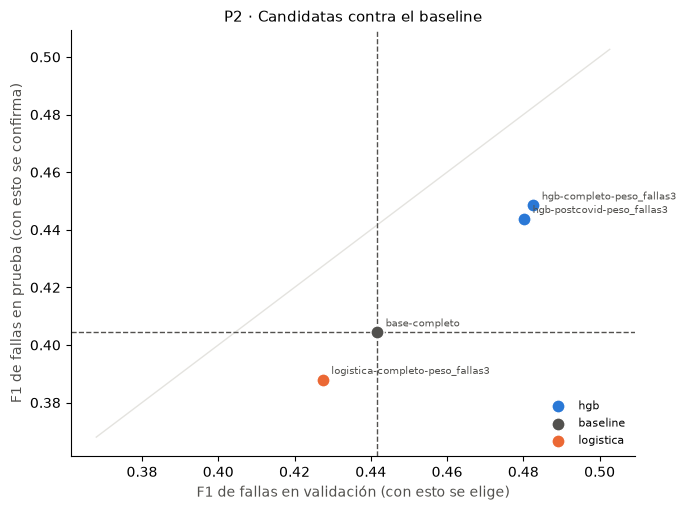

In [5]:
# Objetivo: ver mejora y estabilidad de un vistazo.
# Resultado esperado: un punto por modelo, coloreado por familia, con su nombre.

colores = {"baseline": "#52514e", "hgb": "#2a78d6", "logistica": "#eb6834"}
fig, ax = plt.subplots(figsize=(7, 5.2))
for _, f in comparacion.iterrows():
    ax.scatter(f["val_f1"], f["test_f1"], s=90, color=colores.get(f["familia"], "#1baf7a"), edgecolor="white", zorder=3,
               label=f["familia"])
    ax.annotate(f["corrida"].replace("p2-", ""), (f["val_f1"], f["test_f1"]), textcoords="offset points",
                xytext=(6, 4), fontsize=7, color="#52514e")
ax.axvline(f1_base_val, color="#52514e", linestyle="--", linewidth=1)
ax.axhline(f1_base_test, color="#52514e", linestyle="--", linewidth=1)
limites = [min(comparacion[["val_f1", "test_f1"]].min()) - 0.02, max(comparacion[["val_f1", "test_f1"]].max()) + 0.02]
ax.plot(limites, limites, color="#e4e3df", linewidth=1, zorder=1)  # diagonal: misma cifra en validación y prueba
manijas, etiquetas = ax.get_legend_handles_labels()
unicas = dict(zip(etiquetas, manijas))
ax.legend(unicas.values(), unicas.keys(), frameon=False, fontsize=8, loc="lower right")
ax.set_xlabel("F1 de fallas en validación (con esto se elige)", color="#52514e")
ax.set_ylabel("F1 de fallas en prueba (con esto se confirma)", color="#52514e")
ax.set_title("P2 · Candidatas contra el baseline", fontsize=11)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Propuesta de decisión

La regla, en orden:
1. **Champion:** la candidata con mayor F1 de fallas en **validación**, siempre que en **prueba** también supere al baseline.
2. **Challenger:** la siguiente mejor candidata en validación **que también supere al baseline en prueba**. Un respaldo que sea peor que el baseline no sirve como siguiente mejor: si no hay ninguna, no se asigna challenger.
   *Cambio respecto a la primera versión de la regla:* antes se pedía que el challenger fuera de **otra familia**. Con los resultados, eso elegía la regresión logística, que queda 4 % debajo del baseline en prueba; por eso se cambió.
3. Si dos candidatas quedan a menos de 0.005 en validación, se prefiere la más estable (menor caída de validación a prueba) o la más barata.

La celda siguiente aplica la regla. **La justificación final la escribes tú** en la celda de texto que sigue, con los números de las tablas.

In [6]:
# Objetivo: aplicar la regla de decisión a las candidatas.
# Resultado esperado: el champion y el challenger propuestos, y si el champion le gana al baseline en prueba.

candidatas = comparacion[comparacion["etapa"] == "candidate"].copy()
mejor_val = candidatas["val_f1"].max()
empatadas = candidatas[candidatas["val_f1"] >= mejor_val - 0.005]
champion = empatadas.sort_values(["caida_val_a_test", "segundos_entrenamiento"]).iloc[0]
# Challenger: la siguiente mejor en validación entre las que también le ganan al baseline en prueba.
superan = candidatas[(candidatas["run_id"] != champion["run_id"]) & (candidatas["test_f1"] > f1_base_test)]
challenger = superan.sort_values("val_f1", ascending=False).iloc[0] if not superan.empty else None

for rol, f in [("champion", champion), ("challenger", challenger)]:
    if f is None:
        print(f"{rol:10}: ninguna otra candidata supera al baseline en prueba; no se asigna")
        continue
    print(f"{rol:10}: {f['corrida']} - val {f['val_f1']:.3f} · test {f['test_f1']:.3f} · "
          f"mejora contra el baseline en prueba {f['mejora_test_puntos']:+.3f} ({f['mejora_test_%']:+.1f} %)")
descartadas = candidatas[candidatas["test_f1"] <= f1_base_test]
for _, f in descartadas.iterrows():
    print(f"descartada : {f['corrida']} · test {f['test_f1']:.3f} · "
          f"{f['mejora_test_%']:+.1f} % contra el baseline en prueba")
print("\n¿El champion le gana al baseline en prueba?", "Sí" if champion["test_f1"] > f1_base_test else
      "NO: revisar la decisión antes de registrar")

champion  : p2-hgb-completo-peso_fallas3 - val 0.483 · test 0.449 · mejora contra el baseline en prueba +0.044 (+10.9 %)
challenger: p2-hgb-postcovid-peso_fallas3 - val 0.480 · test 0.444 · mejora contra el baseline en prueba +0.039 (+9.7 %)
descartada : p2-logistica-completo-peso_fallas3 · test 0.388 · -4.1 % contra el baseline en prueba

¿El champion le gana al baseline en prueba? Sí


## 6. Justificación

**Champion: `p2-hgb-completo-peso_fallas3`** (HistGradientBoosting, historia completa, `peso_fallas = 3`, `learning_rate = 0.1`).

- **Mejora contra el baseline:** F1 de fallas de 0.483 en validación y 0.449 en prueba, contra 0.442 y 0.405 del baseline: +0.044 puntos en prueba (+10.9 %). Se eligió con validación y la prueba lo confirmó con una mejora parecida (+0.041 en validación).
- **Métrica de negocio:** el modelo anticipa muchas más fallas reales que el baseline (recall en prueba de 0.481 contra 0.333 en "sin bicicletas" y de 0.537 contra 0.437 en "sin anclajes"), con una precisión parecida (0.369 contra 0.387 y 0.434 contra 0.467). Es decir, se evitan más estaciones vacías o llenas a cambio de una proporción de viajes de camión en vano casi igual.
- **Estabilidad:** baja 0.034 de validación a prueba, un poco menos que el baseline (0.037), así que no se sobreajustó a la validación. En la búsqueda, cambiar el `learning_rate` mueve el F1 0.004 o menos para un mismo `peso_fallas`: el resultado no depende de un ajuste fino.
- **Costo:** es el más caro de entrenar (250 s) y pesa 4.2 MB, pero es el único con la mejor cifra en validación y en prueba; reentrenarlo cada cierto tiempo es viable.
- **Por qué el challenger (`p2-hgb-postcovid-peso_fallas3`):** también supera al baseline en prueba (+0.039, +9.7 %), queda casi igual que el champion y entrena 6.4 veces más rápido (39 s, 1.7 MB) porque usa solo datos desde mayo de 2023. Es un respaldo natural si el reentrenamiento tiene que ser rápido.
- **Descartada:** la regresión logística (0.388 en prueba, −4.1 % contra el baseline). Es la más barata (38 s, 0.1 MB) e interpretable, pero no supera al baseline: la complejidad de HGB sí se justifica.

In [7]:
# Objetivo: guardar la decisión para que registrar_p2.py la ejecute.
# Resultado esperado: el archivo reports/p2_seleccion_modelo.json con los dos run_id y sus métricas.
# Antes de ejecutar: escribe un resumen de tu justificación en JUSTIFICACION (una o dos frases).

JUSTIFICACION = "HGB con historia completa y peso_fallas=3 mejora 10.9 % al baseline en prueba (F1 de fallas 0.449 contra 0.405), anticipa más fallas con precisión parecida y es estable; HGB Post-Covid queda como challenger por ser casi igual de bueno y 6.4 veces más barato de entrenar."

def resumen(f):
    return {"run_id": f["run_id"], "corrida": f["corrida"], "familia": f["familia"],
            "val_f1_fallas": round(float(f["val_f1"]), 4), "test_f1_fallas": round(float(f["test_f1"]), 4),
            "mejora_test_puntos": round(float(f["mejora_test_puntos"]), 4)}

decision = {
    "pregunta": "p2", "modelo_registrado": "mibici-equipo52-p2-riesgo",
    "fecha": datetime.now().isoformat(timespec="seconds"), "experimento": MLFLOW_EXPERIMENT,
    "regla": "champion: mayor val_f1_fallas, confirmado contra el baseline en prueba; challenger: siguiente mejor en validación que también supera al baseline en prueba",
    "baseline": {"run_id": base["run_id"], "val_f1_fallas": round(float(f1_base_val), 4),
                 "test_f1_fallas": round(float(f1_base_test), 4)},
    "champion": resumen(champion), "challenger": resumen(challenger) if challenger is not None else None,
    "justificacion": JUSTIFICACION,
}
ruta = PROJ_ROOT / "reports" / "p2_seleccion_modelo.json"
ruta.write_text(json.dumps(decision, indent=2, ensure_ascii=False))
print("Guardado en", ruta.relative_to(PROJ_ROOT))
print(json.dumps(decision, indent=2, ensure_ascii=False))

Guardado en reports/p2_seleccion_modelo.json
{
  "pregunta": "p2",
  "modelo_registrado": "mibici-equipo52-p2-riesgo",
  "fecha": "2026-10-24T16:58:51",
  "experimento": "mibici-equipo52",
  "regla": "champion: mayor val_f1_fallas, confirmado contra el baseline en prueba; challenger: siguiente mejor en validación que también supera al baseline en prueba",
  "baseline": {
    "run_id": "935914fde71746ddb22bbb7a228500e4",
    "val_f1_fallas": 0.4417,
    "test_f1_fallas": 0.4045
  },
  "champion": {
    "run_id": "d40ea0ba5c6247a79477c804de672cb2",
    "corrida": "p2-hgb-completo-peso_fallas3",
    "familia": "hgb",
    "val_f1_fallas": 0.4827,
    "test_f1_fallas": 0.4486,
    "mejora_test_puntos": 0.0441
  },
  "challenger": {
    "run_id": "be8172dd139d45d2ba201ee23c9eeb1c",
    "corrida": "p2-hgb-postcovid-peso_fallas3",
    "familia": "hgb",
    "val_f1_fallas": 0.4802,
    "test_f1_fallas": 0.4439,
    "mejora_test_puntos": 0.0394
  },
  "justificacion": "HGB con historia completa 